# 02 · Sensitivity analysis

Notebook 01 gave a visual feeling for what the parameters do. Sensitivity
analysis turns that into numbers and answers three different questions that are
often mixed up:

1. **Local sensitivity** – *at my current parameter values*, how much does each
   output change per percent change of each parameter? (Derivatives.)
2. **Identifiability** – given the outputs I measure and their noise, *which
   parameters or parameter combinations can the data determine*? (Derivatives +
   linear algebra.)
3. **Global sensitivity** – *over the whole range in which a parameter is
   uncertain*, how much of the output's variation is due to that parameter, alone
   and through interactions? (Sampling.)

Local methods are cheap (D+1 to 2D runs) but only valid near one point. Global
methods need hundreds to thousands of runs but make no linearity assumption. You
typically use a cheap global *screening* first, then local analysis at the
calibrated point.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc

import driveline as dl
import plotstyle
C = plotstyle.use()
np.set_printoptions(precision=3, suppress=True)
bench = dl.load_bench("A")
D = dl.N_PAR

## 1 · Local sensitivity

We use **logarithmic (relative) sensitivities**

$$S_{ij} = \frac{\partial \ln y_i}{\partial \ln \theta_j} \approx \frac{\%\ \text{change of output } i}{\%\ \text{change of parameter } j}$$

They are dimensionless, so a stiffness in Nm/rad and an inertia in kgm² become
directly comparable. $S=-0.5$ means: +10 % in the parameter gives −5 % in the output.

The derivatives come from **central finite differences** in $\ln\theta$:
$S_j \approx \big[\ln y(\ln\theta + h e_j) - \ln y(\ln\theta - h e_j)\big] / 2h$, i.e. 2·D = 16 runs.

The step $h$ deserves a minute of thought. Too large and the curvature of the
function pollutes the result (truncation error ∝ h²); too small and you divide
numerical noise by a tiny number (round-off error ∝ ε/h). For our analytic
model the sweet spot is wide. **For a time-domain simulation with adaptive step
size it is not**: solver tolerances make the output noisy at the 10⁻⁴…10⁻⁶ level,
and steps of 1–5 % are often needed. Always make this plot once for a new model.

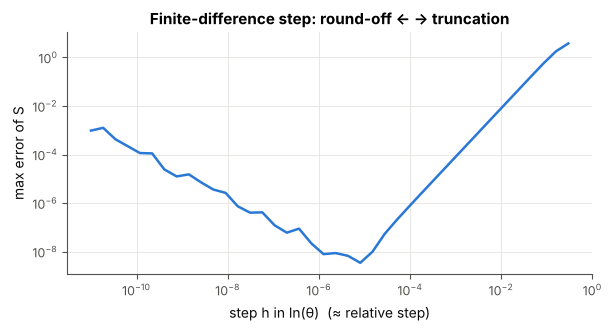

In [2]:
def log_out(lnx):
    """Model outputs as log-amplitudes, shape (2, n_ord, n_rpm)."""
    return np.log(dl.simulate(np.exp(lnx)) + 0.05)


def jacobian(lnx, h=1e-4):
    """Relative sensitivities d ln(y) / d ln(theta), shape (2, n_ord, n_rpm, D)."""
    Jac = np.empty(log_out(lnx).shape + (len(lnx),))
    for j in range(len(lnx)):
        e = np.zeros(len(lnx)); e[j] = h
        Jac[..., j] = (log_out(lnx + e) - log_out(lnx - e)) / (2 * h)
    return Jac


ln0 = np.log(dl.NOMINAL)
ref = jacobian(ln0, 1e-5)
j_kd = dl.NAMES.index("k_damper")
hs = np.geomspace(1e-11, 0.3, 40)
err = [np.abs(jacobian(ln0, h)[..., j_kd] - ref[..., j_kd]).max() for h in hs]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.loglog(hs, err)
ax.set(xlabel="step h in ln(θ)  (≈ relative step)", ylabel="max error of S",
       title="Finite-difference step: round-off ← → truncation")
plt.show()

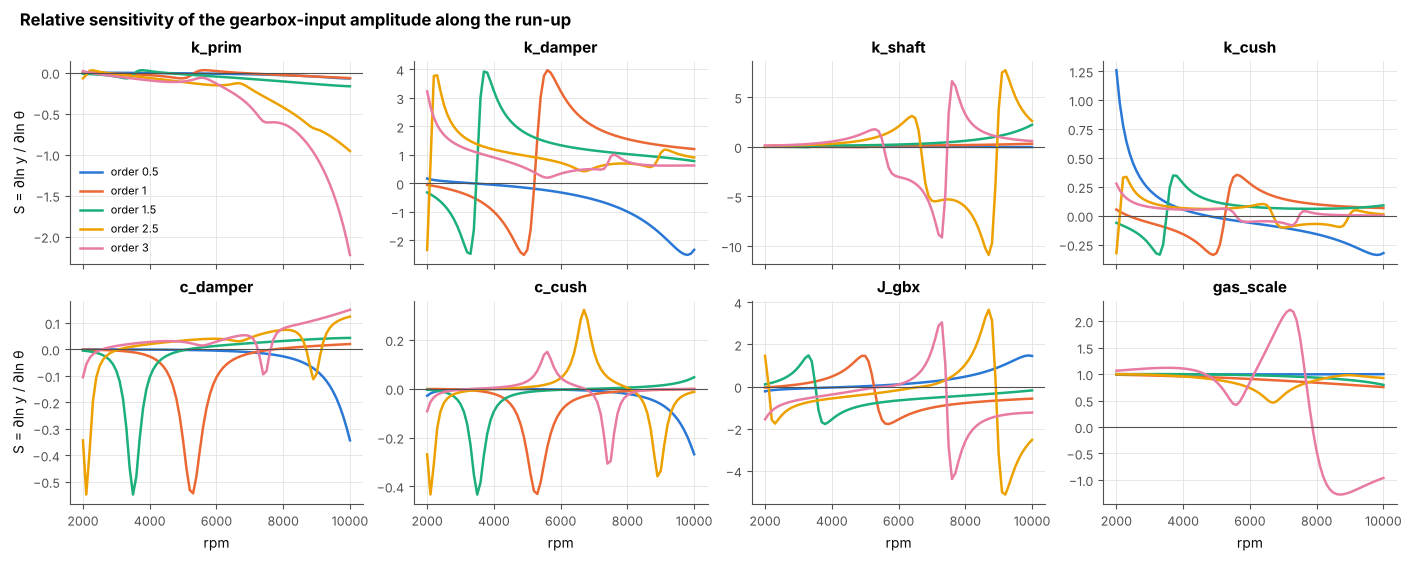

In [3]:
S = jacobian(ln0)                    # (channel, order, rpm, parameter)

fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharex=True)
for a, name in zip(axes.ravel(), dl.NAMES):
    j = dl.NAMES.index(name)
    for o, n in enumerate(dl.ORDERS):
        a.plot(dl.RPM, S[1, o, :, j], color=C[o], label=f"order {n:g}")
    a.axhline(0, color=plotstyle.MUTED, lw=0.8)
    a.set_title(name)
for a in axes[1]:
    a.set_xlabel("rpm")
for a in axes[:, 0]:
    a.set_ylabel("S = ∂ln y / ∂ln θ")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Relative sensitivity of the gearbox-input amplitude along the run-up",
             x=0.01, ha="left", fontweight="bold")
plt.show()

How to read these curves (each is "percent output change per percent parameter change"):

* A stiffness or inertia that **shifts a resonance** produces the characteristic
  S-shaped swing: the amplitude rises on one flank of the peak and falls on the
  other. Large values, but confined to the neighbourhood of a crossing.
* **Damping** produces a one-signed dip exactly at the resonance, nothing elsewhere.
* `gas_scale` gives exactly 1 for the pure gas orders (0.5, 1.5, 2.5) and less
  than 1 for order 1, which has an inertia contribution. For order 3, gas and
  inertia torque partly cancel around 7500 rpm, so the sensitivity swings
  strongly there – a small change of one part changes the small difference a lot.

The curves are the *fingerprints* of the parameters. Two parameters can be told
apart by the data if – and only if – their fingerprints are not proportional to
each other.

A compact overview: RMS sensitivity per parameter and output group.

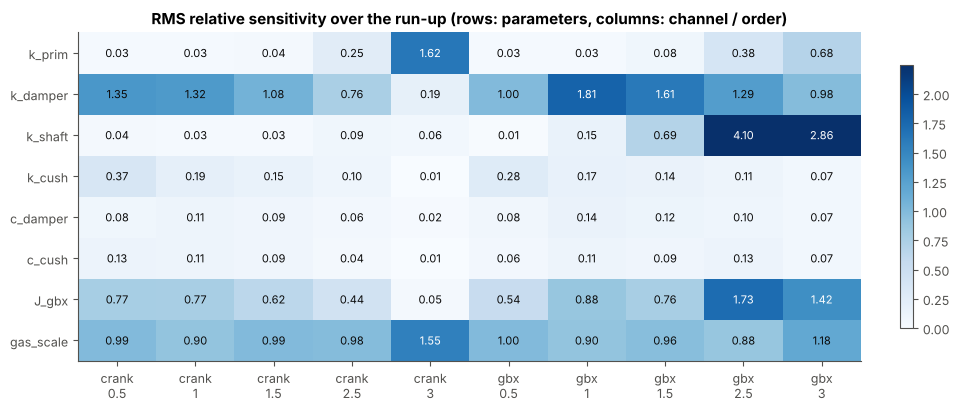

In [4]:
rms = np.sqrt((S ** 2).mean(axis=2))            # (channel, order, parameter)
table = rms.reshape(-1, D).T                    # parameters × (channel, order)
cols = [f"{c}\n{n:g}" for c in dl.CHANNELS for n in dl.ORDERS]
fig, ax = plt.subplots(figsize=(9.5, 4))
im = ax.imshow(table, cmap="Blues", aspect="auto", vmin=0, vmax=np.percentile(table, 98))
ax.set_xticks(range(len(cols)), cols)
ax.set_yticks(range(D), dl.NAMES)
ax.grid(False)
for i in range(D):
    for j in range(len(cols)):
        ax.text(j, i, f"{table[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if table[i, j] > 0.6 * im.get_clim()[1] else plotstyle.INK)
ax.set_title("RMS relative sensitivity over the run-up (rows: parameters, columns: channel / order)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

This table is directly useful for planning measurements: a row with small
numbers everywhere is a parameter this test cannot see; a column with large
numbers in one row only is a measurement that isolates that parameter.
For example, the high orders at the gearbox input carry most of the information
about `k_shaft`, order 3 at the crank is the only place where `k_prim` shows up,
and the rows of `k_cush` and of both damping parameters are pale throughout.

## 2 · From sensitivity to identifiability

Stack all sensitivities into one matrix $\mathbf{S}$ (810 outputs × 8 parameters).
Near the current point the residuals change linearly,
$\Delta\mathbf{r} \approx \mathbf{S}\,\Delta\ln\boldsymbol\theta$. If every output carries independent noise of
standard deviation $\sigma$ (in log units; 0.03 ≈ 3 %), least-squares theory gives
the covariance of the estimated parameters:

$$\operatorname{Cov}(\ln\hat{\boldsymbol\theta}) \approx \sigma^2\,(\mathbf{S}^\top\mathbf{S})^{-1}$$

$\mathbf{S}^\top\mathbf{S}/\sigma^2$ is the **Fisher information matrix**. Three things can be read from it
*before any calibration is run and without any measured data*:

* the expected standard deviation of each parameter (how well it can be pinned down),
* the correlation between parameter estimates (valleys from notebook 01),
* via the singular value decomposition of $\mathbf{S}$: the directions in parameter
  space the data determine well (large singular values) or hardly at all (small).

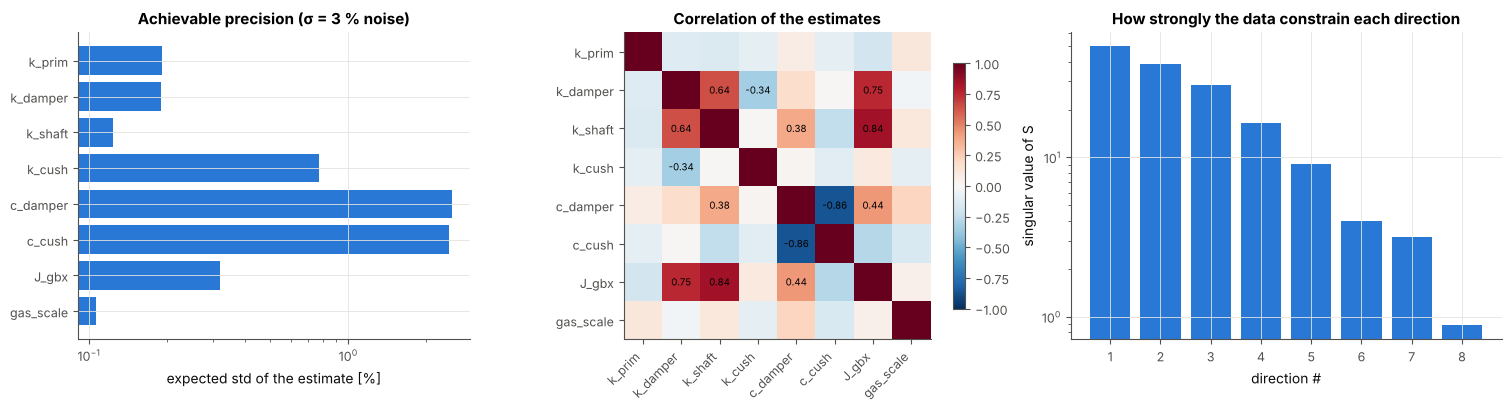

expected std [%]: {'k_prim': 0.19, 'k_damper': 0.19, 'k_shaft': 0.12, 'k_cush': 0.77, 'c_damper': 2.52, 'c_cush': 2.45, 'J_gbx': 0.32, 'gas_scale': 0.11}
condition number of S: 56

best-determined direction : {'k_damper': 0.28, 'k_shaft': 0.85, 'J_gbx': -0.44}
worst-determined direction: {'c_damper': -0.72, 'c_cush': 0.7}


In [5]:
sigma = 0.03
Sm = S.reshape(-1, D)
F = Sm.T @ Sm / sigma ** 2
cov = np.linalg.inv(F)
std = np.sqrt(np.diag(cov))
corr = cov / np.outer(std, std)

fig, ax = plt.subplots(1, 3, figsize=(15, 4), width_ratios=[1, 1.15, 1.1])
ax[0].barh(dl.NAMES[::-1], 100 * std[::-1])
ax[0].set(xscale="log", xlabel="expected std of the estimate [%]",
          title=f"Achievable precision (σ = {100 * sigma:.0f} % noise)")
im = ax[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(D), dl.NAMES, rotation=45, ha="right")
ax[1].set_yticks(range(D), dl.NAMES)
ax[1].grid(False)
for i in range(D):
    for j in range(D):
        if i != j and abs(corr[i, j]) > 0.3:
            ax[1].text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax[1].set_title("Correlation of the estimates")
fig.colorbar(im, ax=ax[1], shrink=0.8)

U_, sv, Vt = np.linalg.svd(Sm, full_matrices=False)
ax[2].bar(range(1, D + 1), sv)
ax[2].set(yscale="log", xlabel="direction #", ylabel="singular value of S",
          title="How strongly the data constrain each direction")
plt.show()

print("expected std [%]:", {n: round(float(v), 2) for n, v in zip(dl.NAMES, 100 * std)})
print(f"condition number of S: {sv[0] / sv[-1]:.0f}")
fmt = lambda v: {n: round(float(c), 2) for n, c in zip(dl.NAMES, v) if abs(c) > 0.05}
print("\nbest-determined direction :", fmt(Vt[0]))
print("worst-determined direction:", fmt(Vt[-1]))

Interpretation:

* Parameters fall into classes. The stiffnesses, `J_gbx` and `gas_scale` should
  be recoverable to a fraction of a percent from this run-up *if the model
  structure is right*; `k_cush` is the weakest of them (its mode lies below the
  run-up). **The two damping values are an order of magnitude worse.**
* The worst-determined direction is not a single parameter but a **mixture**:
  "`c_damper` down, `c_cush` up" (correlation −0.86). Both dampers take energy
  out of mode 2, so the peak heights mainly fix their *combined* effect; how the
  damping is split between clutch and cush drive is much less certain. This is
  the valley picture from notebook 01 in numbers. If you care about the split,
  you need a measurement in which the two act differently.
* `k_prim` looks better here than the flat cost curve in notebook 01 suggested.
  Its information sits entirely in the small order-3 amplitude at the crank
  above 8000 rpm. Whether you trust a 0.2 rad/s signal to 3 % is an engineering
  judgement the formula cannot make for you.
* These numbers assume the model structure is right and the noise is independent.
  Real precision is always worse (notebook 03, data set B). Use them as a
  **ranking and a lower bound**, not as a promise.

**Practical use: design the experiment.** What would a run-down to 1200 rpm add?
At 1200 rpm order 1.5 is at 30 Hz and order 0.5 at 10 Hz – right on mode 1.

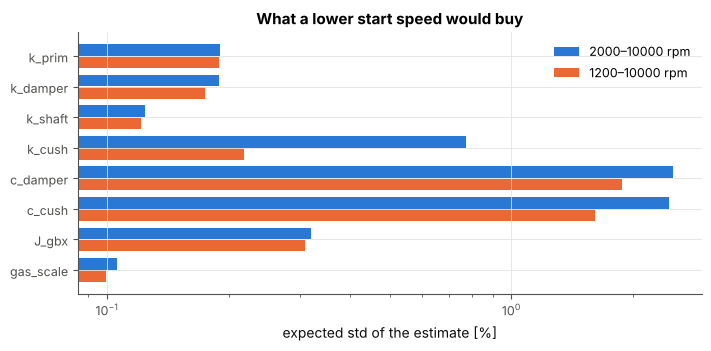

In [6]:
def expected_std(rpm_grid, x=dl.NOMINAL, h=1e-4):
    lnx = np.log(x)
    f = lambda l: np.log(dl.simulate(np.exp(l), rpm=rpm_grid) + 0.05).ravel()
    Sx = np.stack([(f(lnx + h * np.eye(D)[j]) - f(lnx - h * np.eye(D)[j])) / (2 * h) for j in range(D)], 1)
    return np.sqrt(np.diag(np.linalg.inv(Sx.T @ Sx / sigma ** 2)))


std_ext = expected_std(np.arange(1200.0, 10001.0, 100.0))
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(D)
ax.barh(y + 0.2, 100 * std[::-1], 0.38, label="2000–10000 rpm")
ax.barh(y - 0.2, 100 * std_ext[::-1], 0.38, label="1200–10000 rpm")
ax.set_yticks(y, dl.NAMES[::-1])
ax.set(xscale="log", xlabel="expected std of the estimate [%]",
       title="What a lower start speed would buy")
ax.legend()
plt.show()

Extending the run-up downwards improves `k_cush` by a factor of about 3.5, helps
the two damping values moderately and leaves `k_prim` untouched (its mode is at
the other end). This is
model-based test planning: a few milliseconds of simulation tell you which bench
run is worth asking for.

## 3 · Global sensitivity

Local sensitivities describe the neighbourhood of one point. But before
calibration we don't know where the right point is – `c_damper` may be off by a
factor of 5 – and a parameter that is harmless at nominal may be important
elsewhere (remember `k_prim` in notebook 01). Global methods vary all parameters
over their full ranges simultaneously.

### 3.1 Scalar outputs

Global indices are defined per scalar output, so we first pick a few
engineering quantities ("KPIs"). Choosing them is a modelling decision in itself.

In [7]:
i_1 = list(dl.ORDERS).index(1.0)
i_05 = list(dl.ORDERS).index(0.5)
i_3 = list(dl.ORDERS).index(3.0)
KPI = ["peak gbx order-1 ampl.", "rpm of that peak", "gbx order 0.5 @ 2000 rpm",
       "crank order-3 level 7–10k rpm", "cost J vs. bench"]


def kpis(x):
    amp = dl.simulate(x)
    k = amp[1, i_1].argmax()
    r = (np.log(amp + 0.05) - np.log(bench["amp"] + 0.05)).ravel()
    return np.array([amp[1, i_1, k], dl.RPM[k], amp[1, i_05, 0],
                     np.exp(np.mean(np.log(amp[0, i_3, dl.RPM >= 7000]))),
                     np.sqrt(np.mean(r ** 2))])


print(dict(zip(KPI, kpis(dl.NOMINAL).round(3))))

{'peak gbx order-1 ampl.': np.float64(54.039), 'rpm of that peak': np.float64(5200.0), 'gbx order 0.5 @ 2000 rpm': np.float64(45.781), 'crank order-3 level 7–10k rpm': np.float64(0.218), 'cost J vs. bench': np.float64(0.312)}


### 3.2 Morris screening – cheap ranking

The Morris method (elementary effects) is one-at-a-time done properly: take a
random start point, change one parameter by a fixed step Δ, record the output
change, then change the next parameter *from the new point*, and so on. One such
trajectory costs D+1 runs. Repeat for r = 10…50 random trajectories.

For each parameter you get r "elementary effects" $EE = \Delta y/\Delta$ at different
places in the space:

* $\mu^*$ = mean of $|EE|$ → overall importance,
* $\sigma$ = standard deviation of $EE$ → the effect depends on where you are, i.e.
  **nonlinearity or interaction** with other parameters.

With r = 30 that is 270 runs here – affordable even for slow models, which is
why Morris is the standard first step when you have 20–100 uncertain parameters.

270 runs, 0.11 s


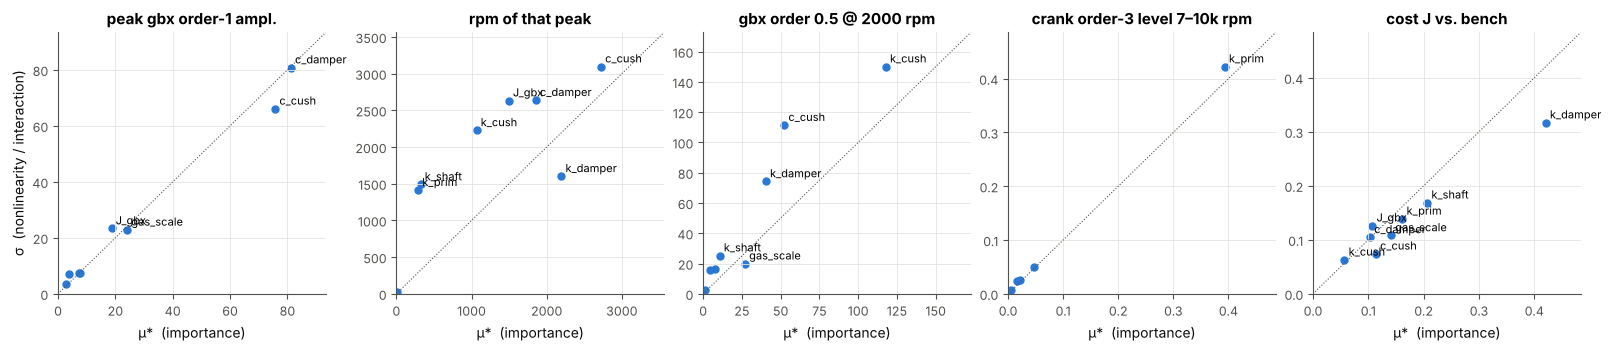

In [8]:
def morris(f, d, r=30, levels=6, seed=0):
    """Elementary effects on the unit cube. Returns array (r, d, n_outputs)."""
    rng = np.random.default_rng(seed)
    delta = levels / (2 * (levels - 1))
    grid = np.arange(levels // 2) / (levels - 1)          # start levels so that u + delta <= 1
    ee = []
    for _ in range(r):
        u = rng.choice(grid, d)
        y = f(u)
        row = np.empty((d, len(y)))
        for j in rng.permutation(d):
            u2 = u.copy(); u2[j] += delta
            y2 = f(u2)
            row[j] = (y2 - y) / delta
            u, y = u2, y2
        ee.append(row)
    return np.array(ee)


f_unit = lambda u: kpis(dl.from_unit(u))
t0 = time.perf_counter()
EE = morris(f_unit, D)
print(f"{EE.shape[0] * (D + 1)} runs, {time.perf_counter() - t0:.2f} s")
mu_star, sig = np.abs(EE).mean(0), EE.std(0)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for k, a in enumerate(axes):
    a.scatter(mu_star[:, k], sig[:, k], s=25, color=C[0])
    for j, n in enumerate(dl.NAMES):
        if mu_star[j, k] > 0.15 * mu_star[:, k].max() or sig[j, k] > 0.15 * sig[:, k].max():
            a.annotate(n, (mu_star[j, k], sig[j, k]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    lim = max(mu_star[:, k].max(), sig[:, k].max()) * 1.15
    a.plot([0, lim], [0, lim], color=plotstyle.MUTED, lw=0.8, ls=":")
    a.set(title=KPI[k], xlabel="μ*  (importance)", xlim=(0, lim), ylim=(0, lim))
axes[0].set_ylabel("σ  (nonlinearity / interaction)")
plt.show()

Points far to the right are important; points near or above the dotted diagonal
act strongly nonlinearly or through interactions. Parameters that stay in the
bottom-left corner for *all* outputs you care about are candidates to fix at
nominal ("factor fixing").

### 3.3 Sobol indices – variance decomposition

Treat the uncertain parameters as random (uniform in the unit cube, i.e.
log-uniform between the bounds). The output $Y$ then has a variance $V(Y)$. Sobol
indices split this variance:

* **First-order index** $S_i = V\big(E[Y\,|\,\theta_i]\big)/V(Y)$: the share of the
  variance that would disappear *on average* if we knew $\theta_i$ exactly. It is
  the variance of the orange "binned mean" line in the scatter plots of notebook 01.
* **Total index** $S_{Ti}$: the share that remains if we knew *everything except*
  $\theta_i$. It includes all interactions of $\theta_i$ with others.

$S_{Ti} \approx 0$ → the parameter can be fixed without changing the output.
$S_{Ti} \gg S_i$ → it acts mainly through interactions. $\sum S_i = 1$ → the model is
additive; the smaller the sum, the more interaction.

**Estimating them** needs a specific sampling trick (Saltelli): two independent
sample matrices A and B (N × D), plus D hybrid matrices AB⁽ⁱ⁾ = "A with column i
taken from B". Total cost N·(D+2) runs. The estimators are two lines:

20480 runs, 8.2 s


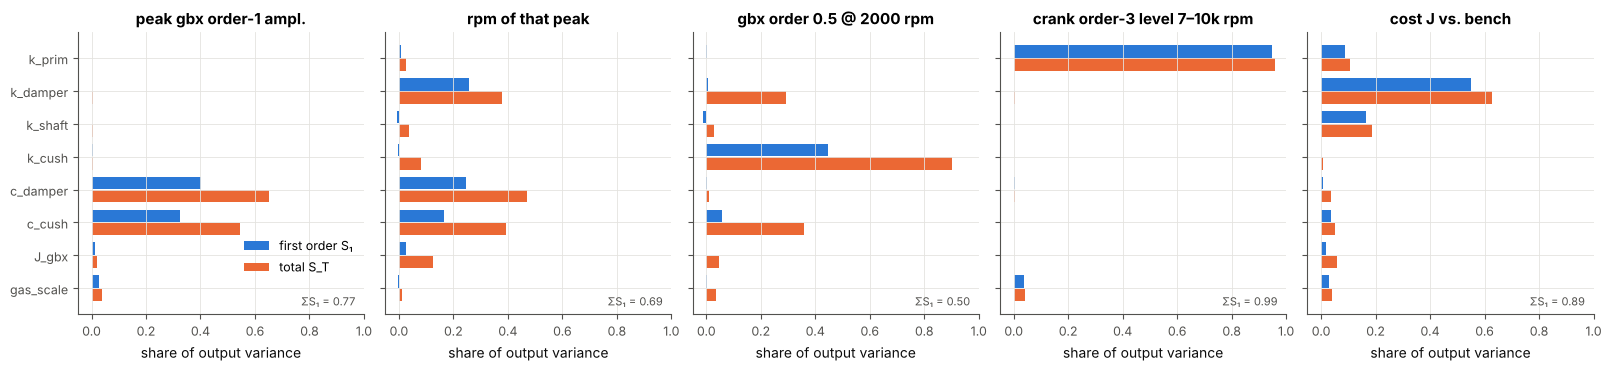

In [9]:
def sobol_indices(f, d, n, seed=0):
    """First-order and total Sobol indices (Saltelli 2010 / Jansen 1999 estimators).

    f maps the unit cube to an output vector. Cost: n*(d+2) evaluations.
    Returns S1, ST with shape (d, n_outputs), and all evaluations for reuse.
    """
    AB = qmc.Sobol(d=2 * d, seed=seed).random(n)
    A, B = AB[:, :d], AB[:, d:]
    fA = np.array([f(u) for u in A])
    fB = np.array([f(u) for u in B])
    var = np.var(np.concatenate([fA, fB]), axis=0)
    S1, ST = [], []
    for i in range(d):
        ABi = A.copy(); ABi[:, i] = B[:, i]
        fABi = np.array([f(u) for u in ABi])
        S1.append(np.mean(fB * (fABi - fA), axis=0) / var)
        ST.append(0.5 * np.mean((fA - fABi) ** 2, axis=0) / var)
    return np.array(S1), np.array(ST)


N = 2048
t0 = time.perf_counter()
S1, ST = sobol_indices(f_unit, D, N)
print(f"{N * (D + 2)} runs, {time.perf_counter() - t0:.1f} s")

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True)
y = np.arange(D)[::-1]
for k, a in enumerate(axes):
    a.barh(y + 0.2, S1[:, k], 0.38, label="first order S₁")
    a.barh(y - 0.2, ST[:, k], 0.38, label="total S_T")
    a.set(title=KPI[k], xlim=(-0.05, 1), xlabel="share of output variance")
    a.text(0.97, 0.03, f"ΣS₁ = {S1[:, k].sum():.2f}", transform=a.transAxes, ha="right",
           fontsize=8, color=plotstyle.MUTED)
axes[0].set_yticks(y, dl.NAMES)
axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 0.1))
plt.show()

Things worth noticing:

* **Each output has its own ranking.** The peak *height* is all damping; the
  low-speed order-0.5 level belongs to the cush drive; the order-3 level at the
  crank is 95 % `k_prim`. "Is parameter X important?" has no answer without "for what?".
* For the peak height, total indices are clearly larger than first-order indices
  (ΣS₁ ≈ 0.8) – interaction. Physically: the two dampers act on the same mode, and
  how much one matters depends on how much damping the other already provides.
* **The "rpm of that peak" KPI is a trap.** One would expect stiffness and inertia
  to dominate, yet damping shows up just as strongly. The reason: with heavy
  damping the resonance bump disappears and `argmax` jumps to the edge of the
  run-up. The KPI is ill-defined in part of the space. Sensitivity analysis is
  very good at exposing such definition problems – surprising indices are a
  prompt to plot the raw samples.
* The **cost J** is dominated by `k_damper`: over these wide ranges, putting the
  main resonance in the wrong place costs far more than anything else. Damping
  hardly registers – although the local analysis showed it *can* be determined
  once the resonances are in place. Global indices of the cost tell you what to
  get right first; local analysis at the optimum tells you what can be pinned down.
* Sobol indices depend on the **ranges** you assume. Halve the range of `c_damper`
  and its share shrinks. They answer "which uncertainty matters most?", which is
  what you want for deciding where to spend measurement effort.

### 3.4 How many runs does this need?

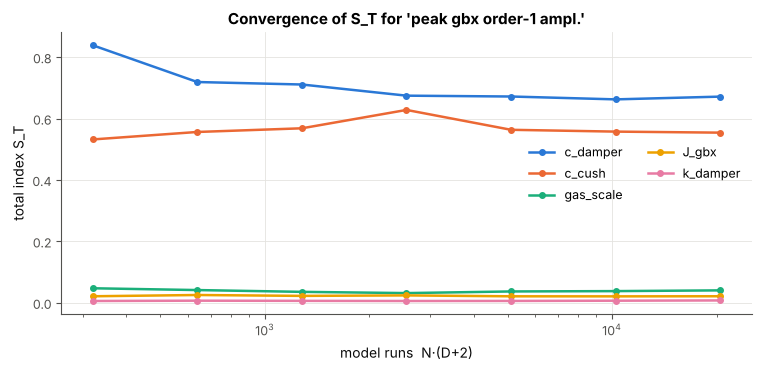

In [10]:
Ns = [32, 64, 128, 256, 512, 1024, 2048]
conv = np.array([sobol_indices(f_unit, D, n, seed=3)[1][:, 0] for n in Ns])   # ST for KPI 0
fig, ax = plt.subplots(figsize=(7.5, 3.6))
top = np.argsort(ST[:, 0])[::-1][:5]
for j, c in zip(top, C):
    ax.plot(np.array(Ns) * (D + 2), conv[:, j], "o-", color=c, label=dl.NAMES[j])
ax.set(xscale="log", xlabel="model runs  N·(D+2)", ylabel="total index S_T",
       title=f"Convergence of S_T for '{KPI[0]}'")
ax.legend(ncol=2)
plt.show()

The *ranking* is right from a few hundred runs; *values* that are stable to
about ±0.05 need a few thousand. That is nothing for a 1 ms model and out of reach
for a 10-minute model. Two ways out, and both are standard practice:

* use **Morris** (hundreds of runs) when a ranking is all you need,
* build a **surrogate** from ~100–200 runs and compute Sobol indices on the
  surrogate (notebook 04).

In real projects use a tested library rather than hand-written estimators.
[SALib](https://salib.readthedocs.io) implements Morris, Sobol (with confidence
intervals), FAST and others behind one interface:

In [11]:
from SALib.sample import sobol as salib_sample
from SALib.analyze import sobol as salib_sobol

problem = dict(num_vars=D, names=dl.NAMES, bounds=[[0.0, 1.0]] * D)
Xs = salib_sample.sample(problem, 1024, calc_second_order=False, seed=0)
Ys = np.array([f_unit(u)[0] for u in Xs])
res = salib_sobol.analyze(problem, Ys, calc_second_order=False, seed=0)
print(f"SALib, {len(Xs)} runs, KPI: {KPI[0]}")
print(f"{'':10s} {'S1':>6s} {'ST':>6s} {'±ST (95%)':>10s}   our ST")
for n, a, b, c, d_ in zip(dl.NAMES, res["S1"], res["ST"], res["ST_conf"], ST[:, 0]):
    print(f"{n:10s} {a:6.2f} {b:6.2f} {c:10.2f}   {d_:6.2f}")

SALib, 10240 runs, KPI: peak gbx order-1 ampl.
               S1     ST  ±ST (95%)   our ST
k_prim      -0.00   0.00       0.00     0.00
k_damper     0.00   0.01       0.00     0.01
k_shaft      0.00   0.00       0.00     0.00
k_cush       0.00   0.00       0.00     0.00
c_damper     0.41   0.66       0.08     0.65
c_cush       0.32   0.56       0.08     0.54
J_gbx        0.01   0.02       0.00     0.02
gas_scale    0.03   0.04       0.01     0.04


## 4 · Summary

| Method | Cost (runs) | Gives you | Use when |
|---|---|---|---|
| Local finite differences | 2·D | sensitivities at one point, fingerprints over rpm | always, at nominal and at the calibrated point |
| Fisher information / SVD | same runs | achievable precision, correlations, unidentifiable directions | before calibrating; for test planning |
| Morris screening | r·(D+1), r ≈ 10–50 | ranking + nonlinearity flag | many parameters, expensive model |
| Sobol indices | N·(D+2), N ≈ 500–5000 | variance shares incl. interactions | cheap model or surrogate |

Take-aways for the driveline example, which notebook 03 will put to the test:

* Stiffnesses, `J_gbx`, `gas_scale` – well determined by this run-up, `k_cush`
  least of them (a lower start speed would help).
* `c_damper` and `c_cush` – their combined effect on mode 2 is determined by the
  peak heights; the split between them is the weakest direction of the problem.
* Over the prior ranges the cost is ruled by `k_damper`: get the resonance
  location right first, the rest follows.

### Try it yourself

1. Repeat the identifiability analysis using only the crank channel (`S[0]`).
   Which parameters lose most? What does that say about the value of the second encoder?
2. Compute the expected precision for a part-load run (`load=0.3` in `dl.simulate`).
   Is `gas_scale` easier or harder to identify, and why?
3. Narrow the bounds of `c_damper` to ×0.7…×1.4 (edit `dl.LOWER`/`dl.UPPER` on a
   copy) and recompute the Sobol indices of the peak height.
4. Add a KPI of your own, e.g. the damper torque amplitude from
   `dl.simulate(..., full_output=True)`.

Next: **03 – Calibration.**